In [1]:
import os
import s3fs

########## CONFIG ##########
GLACIER_NAME  = "zach"
S3_BUCKET     = "s3://gaia"
RESOLUTION    = "MS"                  # MS = monthly on the first of the month
TRAIN_CUTOFF  = "2022-01-01"          # everything before this is train
TEST_START    = "2022-01-01"          # everything from here is test
CACHE_PARQUET = True                  # write flat df to S3 after extraction
MODEL_SEED    = 42                    # random seed to train model
BEESWARM_MAX_POINTS = 200_000         # subsample for the beeswarm plot (plotting all rows takes hours)
SPECIAL_NAME  = "_no_vel"             # include a special signifier to the end of filenames
NOTES         = ("Run with encodings for all feature columns with lags"
                 "and season sin and cosine. Calculating SHAP values of all features using GPU")

FEATURE_COLS = [
    # Spatial vars
    "meltwater", #"ice_velocity",                                   # TODO: Add ice_elevation, distance_to_terminus
    # Non-spatial vars (broadcast)
    "airtemp", "masked_mel_velocity", "melange_area_km2", 
    "ocean_EN4_TFc", "area_km2", "area_change_km2",                 # TODO: Add tongue_length, average_meltwater_runoff, melange_rigidity
    # Lag features
    *[f"{lag}_{var}" for var in ["meltwater", "airtemp", "masked_mel_velocity", "melange_area_km2",
                                 "ocean_EN4_TFc", "area_km2", "area_change_km2"]
      for lag in ("lag_1step", "lag_60d", "lag_90d")],      # no discharge lags (target)
    # "roll_30d_mean", "roll_30d_std",
    # Time encodings
    "season_sin", "season_cos",
    # "year_norm", "time_days",
    # Space
    "x", "y",
]

NON_SEASONAL_VARS = [
    # Spatial vars
    "meltwater", #"ice_velocity",
    # Non-spatial vars
    "airtemp", "masked_mel_velocity", "melange_area_km2",
    "ocean_EN4_TFc", "area_km2", "area_change_km2",
    # Space
    "x", "y",
]

TARGET_COL = "Discharge (Gt/yr)"

########## S3 Setup ##########
fs = s3fs.S3FileSystem(
    key=os.environ["AWS_ACCESS_KEY_ID"],
    secret=os.environ["AWS_SECRET_ACCESS_KEY"],
    client_kwargs={"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    config_kwargs={
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
                }
)

storage_options = {
    "client_kwargs": {"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    "config_kwargs": {
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
    },
}

########## Paths shared between scripts ##########
TRAIN_PATH = f"{S3_BUCKET}/cjense/data/testmodel/train_{RESOLUTION}{SPECIAL_NAME}.parquet"
TEST_PATH  = f"{S3_BUCKET}/cjense/data/testmodel/test_{RESOLUTION}{SPECIAL_NAME}.parquet"
cache_path = f"{S3_BUCKET}/cjense/data/testmodel/flat_{RESOLUTION}{SPECIAL_NAME}.parquet"

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
train = pd.read_parquet(cache_path, storage_options=storage_options)

In [ ]:
train

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import xgboost as xgb
import s3fs
from functools import reduce
import os
import shap
import matplotlib.pyplot as plt
from geoshapley import GeoShapleyTreeExplainer
import pickle

# ─────────────────────────────────────────────
# CONFIG — edit these
# ─────────────────────────────────────────────
GLACIER_NAME  = "zach"           # change to glacier_B for second run
S3_BUCKET     = "s3://gaia"
RESOLUTION    = "30D"                  # "6D" or "1D" — start with 6D
TRAIN_CUTOFF  = "2022-01-01"          # everything before this is train
TEST_START    = "2022-01-01"          # everything from here is test
# CACHE_PARQUET = True                  # write flat df to S3 after extraction
RANDOM_SEED   = 42

fs = s3fs.S3FileSystem(
    key=os.environ["AWS_ACCESS_KEY_ID"],
    secret=os.environ["AWS_SECRET_ACCESS_KEY"],
    client_kwargs={"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    config_kwargs={
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
                }
)

storage_options = {
    "client_kwargs": {"endpoint_url": os.environ["S3_ENDPOINT_URL"]},
    "config_kwargs": {
        "request_checksum_calculation": "when_required",
        "response_checksum_validation": "when_required",
    },
}

# FEATURE_COLS = [
#     # Spatial vars
#     "meltwater", #"ice_velocity",                                    # TODO: Add ice_elevation, distance_to_terminus
#     # Non-spatial vars (broadcast)
#     "airtemp", "masked_mel_velocity", "melange_area_km2", 
#     "ocean_EN4_TFc", "area_km2", "area_change_km2",                 # TODO: Add tongue_length, average_meltwater_runoff, melange_rigidity
#     # Lag features
#     # "lag_1step", #"lag_30d", 
#     # "lag_60d", "lag_90d",
#     # "roll_30d_mean", "roll_30d_std",
#     # Time (encoded features only — raw datetime kept separate)
#     "season_sin", "season_cos",
#     # "year_norm", "time_days",
#     # Space
#     "x", "y",
# ]

FEATURE_COLS=['x', 'y', 'meltwater', #"ice_velocity",
       'airtemp',
       'masked_mel_velocity', 
       'melange_area_km2', 'ocean_EN4_TFc',
        'area_km2', 'area_change_km2',
        'lag_1step', 'lag_30d','lag_60d', 'lag_90d', 'roll_30d_mean', 'roll_30d_std',
        'season_sin',
        'season_cos', 
        # 'year_norm', 
       'time_days',
    #    'lag_1step_meltwater',
    #    'lag_30d_meltwater', 'lag_60d_meltwater', 'lag_90d_meltwater',
    #    'roll_30d_mean_meltwater', 'roll_30d_std_meltwater',
    #    'lag_1step_airtemp', 'lag_30d_airtemp', 'lag_60d_airtemp',
    #    'lag_90d_airtemp', 'roll_30d_mean_airtemp', 'roll_30d_std_airtemp',
    #    'lag_1step_masked_mel_velocity', 'lag_30d_masked_mel_velocity',
    #    'lag_60d_masked_mel_velocity', 'lag_90d_masked_mel_velocity',
    #    'roll_30d_mean_masked_mel_velocity', 'roll_30d_std_masked_mel_velocity',
    #    'lag_1step_melange_area_km2', 'lag_30d_melange_area_km2',
    #    'lag_60d_melange_area_km2', 'lag_90d_melange_area_km2',
    #    'roll_30d_mean_melange_area_km2', 'roll_30d_std_melange_area_km2',
    #    'lag_1step_ocean_EN4_TFc', 'lag_30d_ocean_EN4_TFc',
    #    'lag_60d_ocean_EN4_TFc', 'lag_90d_ocean_EN4_TFc',
    #    'roll_30d_mean_ocean_EN4_TFc', 'roll_30d_std_ocean_EN4_TFc',
    #    'lag_1step_area_km2', 'lag_30d_area_km2', 'lag_60d_area_km2',
    #    'lag_90d_area_km2', 'roll_30d_mean_area_km2', 'roll_30d_std_area_km2',
    #    'lag_1step_area_change_km2', 'lag_30d_area_change_km2',
    #    'lag_60d_area_change_km2', 'lag_90d_area_change_km2',
    #    'roll_30d_mean_area_change_km2', 'roll_30d_std_area_change_km2',
    #    'lag_1step_discharge', 'lag_30d_discharge', 'lag_60d_discharge',
    #    'lag_90d_discharge', 'roll_30d_mean_discharge',
    #    'roll_30d_std_discharge'
       ]
TARGET_COL = "discharge"

In [2]:
print("reading parquet")
# df = pd.read_parquet('s3://gaia/cjense/data/testmodel/monthlymean_testdata.parquet', storage_options=storage_options)
df = pd.read_parquet('/Users/cjense/Downloads/flat_30D2_novelocity.parquet')
# df = pd.read_parquet('/Users/cjense/Downloads/flat_30D2.parquet')

# ns = pd.read_parquet(
#     f"{S3_BUCKET}/cjense/data/testmodel/{GLACIER_NAME}_non_spatial.parquet",
#     storage_options=storage_options
# )
# df = df.reset_index()
# ns = ns.reset_index()
# ns["time"] = pd.to_datetime(ns["time"]).dt.normalize()
df["time"] = pd.to_datetime(df["time"])

# df = df.drop(columns=["index"])
# ns = ns.drop(columns=["index"])

# df = df.merge(ns, on="time", how="outer")
# df = df.drop(columns=["index_x", "index_y"])

# print("Merged spatial and non-spatial dataframes.")
# print(df.head())

df = df.resample("ME", on='time').mean().reset_index()
resolution_days = int(RESOLUTION.replace("D", ""))

reading parquet


In [3]:
resolution_days=30
"""
Add lag, rolling, and time-encoding features.
All lags are in timesteps, not days — adjust shift() values if changing resolution.

Lag features are critical with one glacier: the model learns entirely from
space × time variation, so velocity history at each pixel is a strong signal.
"""
df = df.sort_values(["x", "y", "time"]).reset_index(drop=True)
px = df.groupby(["x", "y"])

# ── Velocity lags (in timesteps) ──
steps_30d  = max(1, round(30  / resolution_days))
steps_60d  = max(1, round(60  / resolution_days))
steps_90d  = max(1, round(90  / resolution_days))

non_seasonal_vars=[
    # 'x', 'y', 
        'meltwater', #"ice_velocity",
       'airtemp',
       'masked_mel_velocity', 
       'melange_area_km2', 'ocean_EN4_TFc',
        'area_km2', 'area_change_km2',
        'lag_1step', 'lag_30d','lag_60d', 'lag_90d', 'roll_30d_mean', 'roll_30d_std',
        'season_sin',
        'season_cos', 
        'year_norm', 
       'time_days',
]

for feature in non_seasonal_vars:
    df["lag_1step_"+feature] = px[feature].shift(1)
    df["lag_30d_"+feature]   = px[feature].shift(steps_30d)
    df["lag_60d_"+feature]   = px[feature].shift(steps_60d)
    df["lag_90d_"+feature]   = px[feature].shift(steps_90d)

    # Rolling mean over past ~30 days (excludes current timestep via shift first)
    df["roll_30d_mean_"+feature] = (
        px[feature]
        .transform(lambda s: s.shift(1).rolling(steps_30d, min_periods=1).mean())
    )
    df["roll_30d_std_"+feature] = (
        px[feature]
        .transform(lambda s: s.shift(1).rolling(steps_30d, min_periods=1).std())
    )

# ── Time features ──
t = pd.to_datetime(df["time"])

# Cyclic seasonality — prevents Dec/Jan discontinuity
df["season_sin"] = np.sin(2 * np.pi * t.dt.dayofyear / 365.25).astype("float32")
df["season_cos"] = np.cos(2 * np.pi * t.dt.dayofyear / 365.25).astype("float32")

# Long-term trend (0.0 = year 2000, 1.0 = year 2025)
df["year_norm"] = ((t.dt.year - 2000) / 25).astype("float32")

# Integer time (days since 2000-01-01) — useful as raw feature too
df["time_days"] = (t - pd.Timestamp("2000-01-01")).dt.days.astype("int16")

print(df.keys())

Index(['time', 'level_0', 'index', 'index_x', 'x', 'y', 'meltwater', 'index_y',
       'airtemp', 'masked_mel_velocity',
       ...
       'lag_60d_year_norm', 'lag_90d_year_norm', 'roll_30d_mean_year_norm',
       'roll_30d_std_year_norm', 'lag_1step_time_days', 'lag_30d_time_days',
       'lag_60d_time_days', 'lag_90d_time_days', 'roll_30d_mean_time_days',
       'roll_30d_std_time_days'],
      dtype='str', length=133)


/var/folders/z2/t78xbk451n74r4q5p4w1zt640000gn/T/ipykernel_38595/1975774115.py:42: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["roll_30d_std_"+feature] = (
/var/folders/z2/t78xbk451n74r4q5p4w1zt640000gn/T/ipykernel_38595/1975774115.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["lag_1step_"+feature] = px[feature].shift(1)
/var/folders/z2/t78xbk451n74r4q5p4w1zt640000gn/T/ipykernel_38595/1975774115.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many ti

In [4]:


# df = engineer_features(df, resolution_days=resolution_days)
# df = optimize_dtypes(df)
# print("Datatypes optimized")

# cache_path = f"{S3_BUCKET}/cjense/data/testmodel/flat_{RESOLUTION}2_novelocity.parquet"
# print(f"Writing flat parquet to {cache_path} ...")
# df.to_parquet(cache_path, storage_options=storage_options, index=False)
# print("Cached.")

# df = pd.read_parquet(f"{S3_BUCKET}/cjense/data/testmodel/flat_{RESOLUTION}2_novelocity.parquet", storage_options=storage_options)

df = df.dropna(subset=['discharge'])

train = df[df["time"] <  TRAIN_CUTOFF].copy()
test  = df[df["time"] >= TEST_START].copy()
print(f"Train: {len(train):,} rows  |  Test: {len(test):,} rows")


Train: 238 rows  |  Test: 48 rows


In [5]:


# Drop rows with NaN in any feature (from lag windows at start of timeseries)
dtrain = xgb.DMatrix(train[FEATURE_COLS], label=train[TARGET_COL])
dtest  = xgb.DMatrix(test[FEATURE_COLS],  label=test[TARGET_COL])

params = {
    "tree_method":      "hist",
    "device":           "cuda",       # GPU on Tillicum
    "objective":        "reg:squarederror",
    "eval_metric":      ["rmse", "mae"],
    "max_depth":        6,
    "eta":              0.05,
    "subsample":        0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 10,           # regularize — 140k pixels, don't overfit spatially
    "seed":             RANDOM_SEED,
}

model = xgb.train(
    params,
    dtrain,
    num_boost_round=1000,
    evals=[(dtrain, "train"), (dtest, "test")],
    early_stopping_rounds=50,
    verbose_eval=25,
)


[0]	train-rmse:2.07541	train-mae:1.82278	test-rmse:3.30596	test-mae:3.26014
[25]	train-rmse:0.68765	train-mae:0.55456	test-rmse:1.17076	test-mae:1.10620
[50]	train-rmse:0.30704	train-mae:0.20345	test-rmse:0.49975	test-mae:0.42421


/Users/cjense/Desktop/phd/negis-seasonality/seasonality-model/.pixi/envs/default/lib/python3.14/site-packages/xgboost/callback.py:385: UserWarning: [08:33:17] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1789510470680/work/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[75]	train-rmse:0.20017	train-mae:0.11060	test-rmse:0.33446	test-mae:0.26012
[100]	train-rmse:0.16243	train-mae:0.08849	test-rmse:0.30062	test-mae:0.20687
[125]	train-rmse:0.14059	train-mae:0.07823	test-rmse:0.31316	test-mae:0.21426
[150]	train-rmse:0.12490	train-mae:0.07051	test-rmse:0.32174	test-mae:0.22020
[164]	train-rmse:0.11634	train-mae:0.06564	test-rmse:0.32145	test-mae:0.21968


In [6]:


dtest = xgb.DMatrix(test[FEATURE_COLS])
preds = model.predict(dtest)
truth = test[TARGET_COL].values

# Mask NaN in truth only — can't compute metrics on unknown ground truth
valid = ~np.isnan(truth)
preds = preds[valid]
truth = truth[valid]

rmse = np.sqrt(np.mean((preds - truth) ** 2))
mae  = np.mean(np.abs(preds - truth))
truth_var = np.sum((truth - truth.mean()) ** 2)
r2 = 1 - np.sum((truth - preds) ** 2) / truth_var if truth_var > 0 else float("nan")

# Guard against zero-variance truth
# truth_var = np.sum((truth - truth.mean()) ** 2)
# if truth_var == 0:
#     print("  WARNING: truth has zero variance — R² undefined")
#     r2 = float("nan")
# else:
#     r2 = 1 - np.sum((truth - preds) ** 2) / truth_var

print(f"\n── Test metrics ──────────────────")
print(f"  RMSE : {rmse:.4f} Gt/yr")
print(f"  MAE  : {mae:.4f} Gt/yr")
print(f"  R²   : {r2:.4f}")

importance = model.get_score(importance_type="gain")
importance = pd.Series(importance).sort_values(ascending=False)
print(f"\n── Top 10 features by gain ───────")
print(importance.head(10).to_string())



── Test metrics ──────────────────
  RMSE : 0.3215 Gt/yr
  MAE  : 0.2197 Gt/yr
  R²   : 0.6566

── Top 10 features by gain ───────
lag_30d                17.770676
lag_1step              15.754977
roll_30d_mean          12.760436
time_days               8.700774
lag_60d                 2.581374
season_cos              0.612301
masked_mel_velocity     0.311628
airtemp                 0.288863
area_change_km2         0.252534
lag_90d                 0.237210


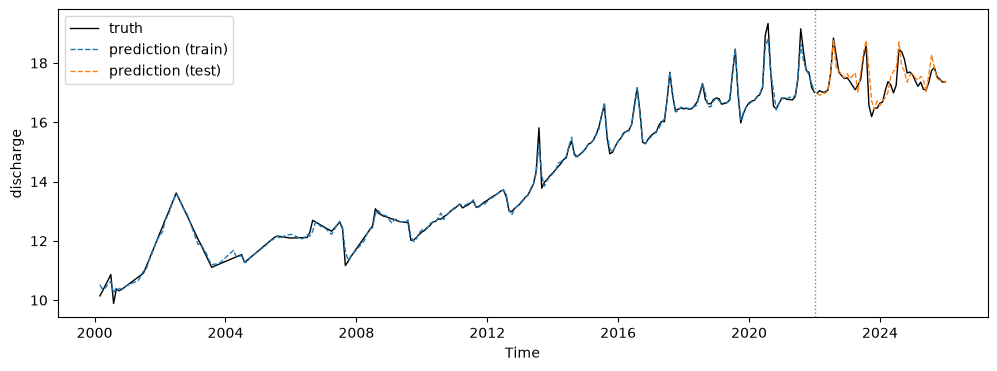

In [7]:
"""Time series of truth vs. predictions over both the train and test periods."""
fig, ax = plt.subplots(figsize=(12, 4))
for df, label, color in [(train, "train", "tab:blue"), (test, "test", "tab:orange")]:
        df = df.sort_values("time")
        preds = model.predict(xgb.DMatrix(df[FEATURE_COLS]))
        ax.plot(df["time"], df[TARGET_COL], color="black", linewidth=1,
                label="truth" if label == "train" else None)
        ax.plot(df["time"], preds, color=color, linewidth=1, linestyle="--",
                label=f"prediction ({label})")

# mark where train data ends and test data begins
ax.axvline(pd.Timestamp(TRAIN_CUTOFF), color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("Time")
ax.set_ylabel(TARGET_COL)
ax.legend()
# fig.savefig('./figures/xgboost_result.png', dpi=300, bbox_inches='tight')
# plt.close(fig)

In [9]:


# Heatmap plot
combined = pd.concat([train, test], ignore_index=True).sort_values("time").reset_index(drop=True)
shap_vals_combined = explainer(combined[FEATURE_COLS])
try:
    print("saving shap vals to csv")
    shap_df = pd.DataFrame(shap_vals_combined.values, columns=train.columns)

    # Save to a CSV file
    shap_df.to_csv(f'./shap_values{RESOLUTION}_seed{RANDOM_SEED}.csv', index=False)
except:
    print("saving shap vals to pickle")
    with open(f'./shap_values{RESOLUTION}_seed{RANDOM_SEED}.pkl', 'wb') as f:
        pickle.dump(shap_vals_combined, f)

times_combined = combined["time"]
instance_order = np.arange(len(times_combined))

ax = shap.plots.heatmap(shap_vals_combined[:, non_seasonal_vars], instance_order=instance_order, show=False)
ax.set_aspect("auto")
ax.figure.set_size_inches(20, 5)

# label the x-axis with the year instead of a raw instance index
year_change = times_combined.dt.year.ne(times_combined.dt.year.shift(1))
tick_pos = np.flatnonzero(year_change.to_numpy())
tick_labels = times_combined.dt.year.iloc[tick_pos].astype(str)
ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labels, rotation=0)
ax.set_xlabel("Year")

# mark where train data ends and test data begins
split_idx = np.searchsorted(times_combined.values, np.datetime64(TRAIN_CUTOFF))
# ax.axvline(split_idx - 0.5, color="black", linestyle="--", linewidth=1)

saving shap vals to csv
saving shap vals to pickle


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [ ]:
# model_path = f"/gpfs/scrubbed/jensencc/negis-seasonality/seasonality-model/models/{GLACIER_NAME}_xgb_{RESOLUTION}2_novelocity.json"
# model.save_model(model_path)
# fs.put(model_path, f"{S3_BUCKET}/cjense/data/testmodel/{GLACIER_NAME}_xgb_{RESOLUTION}2_novelocity.json")
# print(f"\nModel saved to S3.")

# feature_cols = model.get_booster().feature_names

masker = shap.maskers.Independent(train[FEATURE_COLS], max_samples=len(train))
explainer = shap.TreeExplainer(model, masker)
shap_vals = explainer(test[FEATURE_COLS])

# Beeswarm plot
shap.plots.beeswarm(shap_vals_combined[:, non_seasonal_vars], show=False, max_display=len(FEATURE_COLS))
# plt.savefig('./figures/beeswarm.png', dpi=300, bbox_inches='tight')


NameError: name 'shap_vals_combined' is not defined

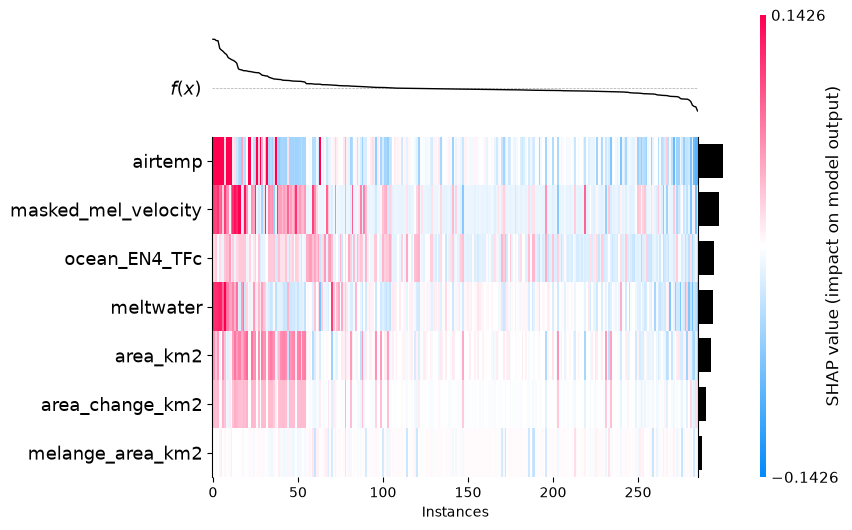

<Axes: xlabel='Instances'>

In [ ]:

shap.plots.heatmap(shap_vals_combined[:, non_seasonal_vars], instance_order=shap_vals_combined[:, non_seasonal_vars].sum(1))

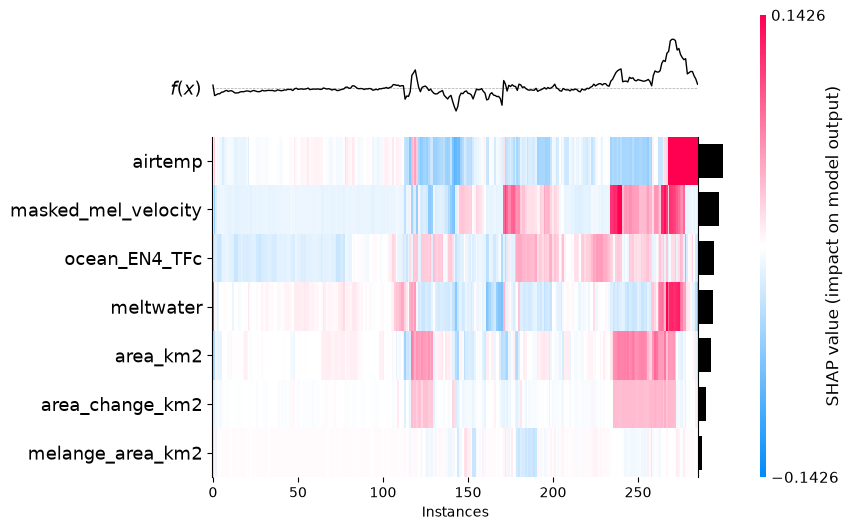

<Axes: xlabel='Instances'>

In [ ]:
shap.plots.heatmap(shap_vals_combined[:, non_seasonal_vars])

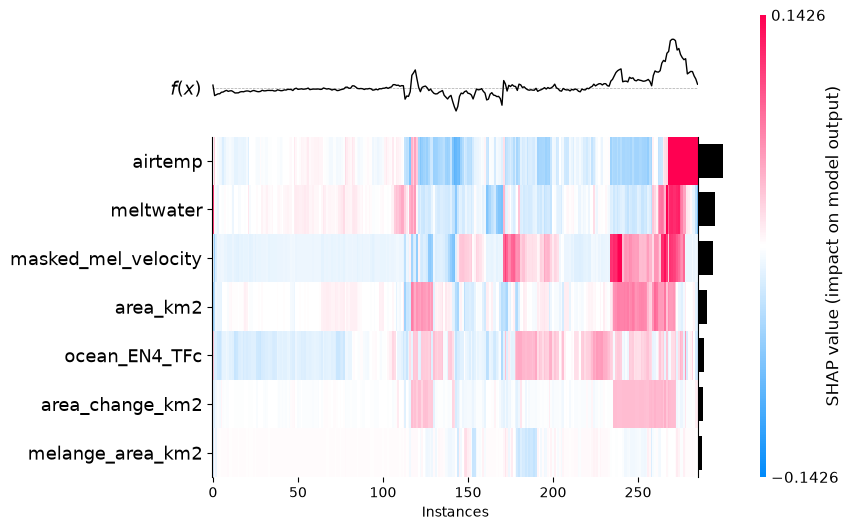

<Axes: xlabel='Instances'>

In [ ]:
shap.plots.heatmap(shap_vals_combined[:, non_seasonal_vars], feature_values=shap_vals_combined[:, non_seasonal_vars].abs.max(0))

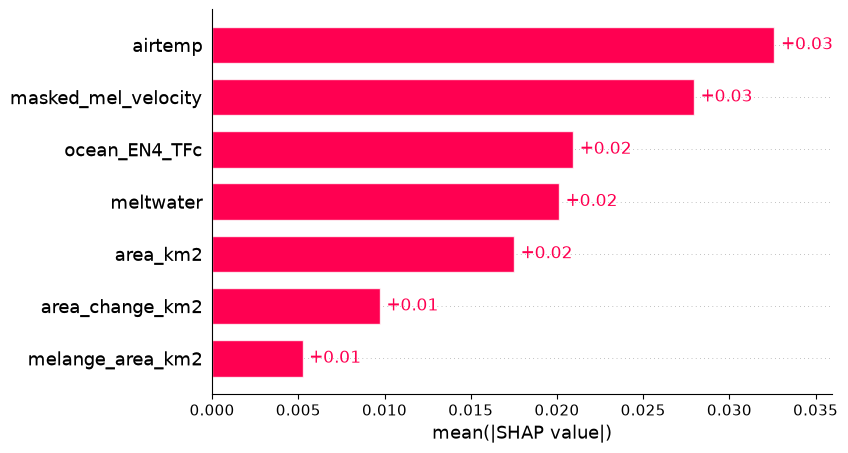

In [ ]:
shap.plots.bar(shap_vals_combined[:, non_seasonal_vars], max_display=15)

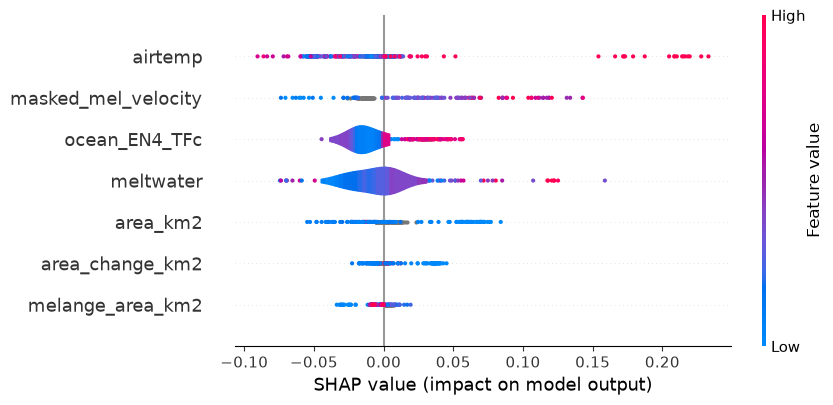

In [ ]:
shap.plots.violin(shap_vals_combined[:, non_seasonal_vars])

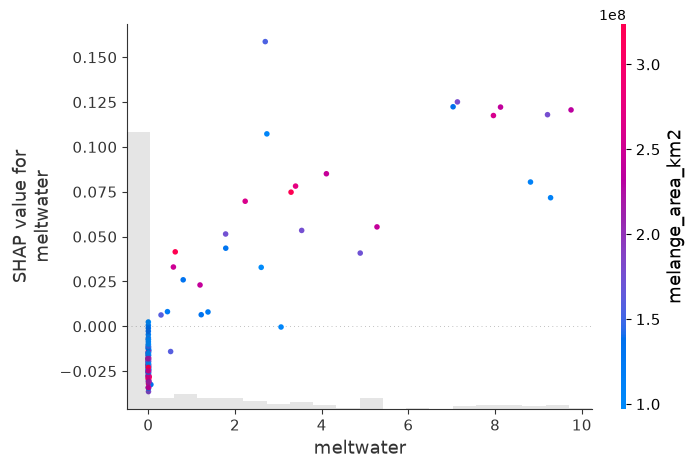

In [ ]:
shap.plots.scatter(shap_vals_combined[:, "meltwater"], color=shap_vals_combined)

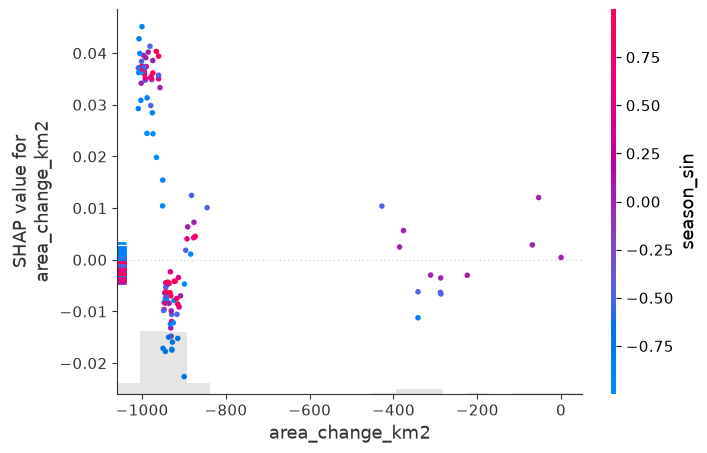

In [ ]:
shap.plots.scatter(shap_vals_combined[:, "area_change_km2"], color=shap_vals_combined)

In [ ]:
shap.initjs()
shap.plots.force(shap_vals_combined[:, non_seasonal_vars])